# Q4 (b)–(e): single-scan baseline, belief filter, heatmap, corrupted beams

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
D = 'SeDriCa_perception_starter_data/localization/'
ref = pd.read_csv(D + 'reference_scans.csv')
obs = pd.read_csv(D + 'observed_scans.csv')
beams = [c for c in ref.columns if c.startswith('r_')]
R = ref[beams].values                  # (8, 31) map fingerprints
O = obs[beams].values                  # (12, 31) observed scans, used as given

### Least mean absolute error place per time step

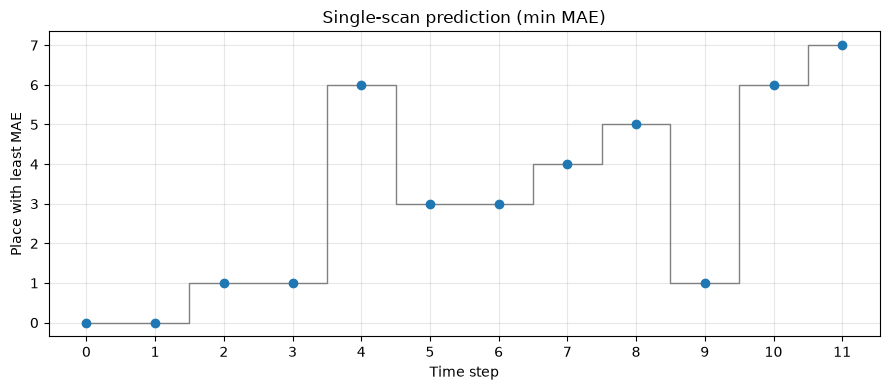

[0, 0, 1, 1, 6, 3, 3, 4, 5, 1, 6, 7]


In [2]:
mae = np.abs(O[:, None, :] - R[None, :, :]).mean(axis=2)   # (12, 8)
best = mae.argmin(axis=1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.step(obs.time_step, best, where='mid', color='gray', lw=1)
ax.plot(obs.time_step, best, 'o', color='tab:blue')
ax.set(xlabel='Time step', ylabel='Place with least MAE', title='Single-scan prediction (min MAE)', yticks=range(8), xticks=obs.time_step)
ax.grid(alpha=.3); plt.tight_layout(); plt.show()
print(best.tolist())

### Time steps 4, 8, 9: mean absolute error vs every place

In [3]:
steps = [4, 8, 9]
tab = mae[steps]                                       # raw scans
pd.DataFrame(tab.round(4), index=[f'step {s}' for s in steps], columns=[f'place {p}' for p in range(8)])

,place 0,place 1,place 2,place 3,place 4,place 5,place 6,place 7
step 4,0.6286,0.4351,0.3129,0.3485,0.6139,0.4204,0.2988,0.3361
step 8,0.5303,0.3854,0.4038,0.4892,0.5155,0.3721,0.3913,0.4791
step 9,0.2354,0.0874,0.2223,0.3767,0.2206,0.0899,0.2370,0.3914


### Observed scans at time steps 4, 8, 9

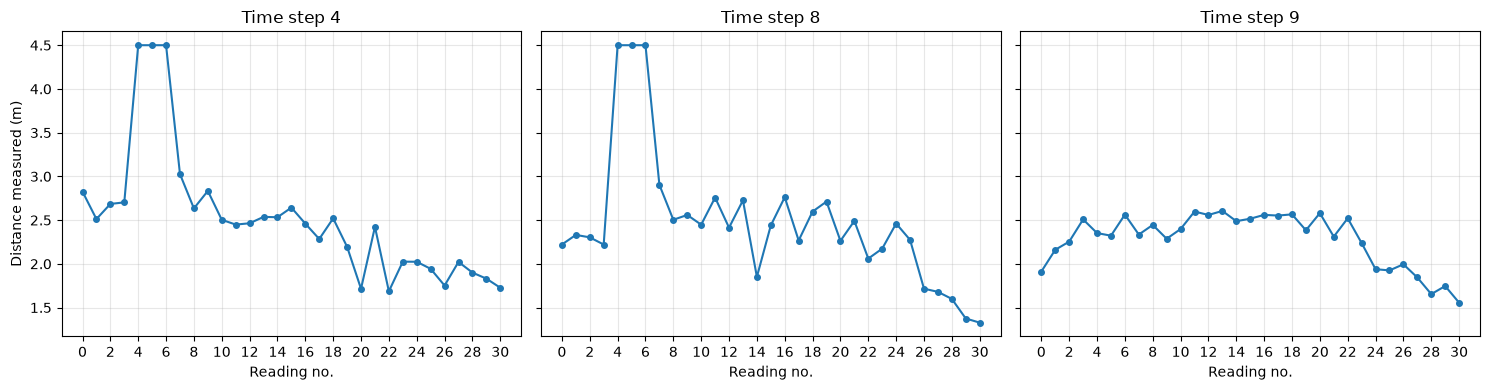

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, t in zip(axs, [4, 8, 9]):
    ax.plot(range(31), O[t], 'o-', ms=4, color='tab:blue')
    ax.set(title=f'Time step {t}', xlabel='Reading no.')
    ax.set_xticks(range(0, 31, 2)); ax.grid(alpha=.3)
axs[0].set_ylabel('Distance measured (m)')
plt.tight_layout(); plt.show()

### Explanation
- **Steps 4, 8:** three beams (-55°, -50°, -45°) read exactly 4.5 m, likely the sensor limit (map max ≈ 3.09 m). They are invalid and inflate every place's error.
- **Step 9:** place 1 (0.0874) and place 5 (0.0899) nearly tie. This is the look-alike pair, so odometry is needed to decide (expected: 5).

### Interpolating the 4.5 m beams
Each 4.5 m reading is replaced by a straight line between the nearest valid beams on either side.

In [5]:
ang = np.arange(-75, 80, 5)
Oc = O.copy()
for t in range(len(Oc)):
    bad = Oc[t] >= 4.5
    if bad.any():
        Oc[t, bad] = np.interp(ang[bad], ang[~bad], Oc[t, ~bad])
        print(f'step {t}: beams {ang[bad].tolist()} deg -> {Oc[t, bad].round(3).tolist()} m')
mae_clean = np.abs(Oc[:, None, :] - R[None, :, :]).mean(axis=2)
pd.DataFrame(mae_clean[steps].round(4), index=[f'step {s}' for s in steps], columns=[f'place {p}' for p in range(8)])

step 4: beams [-55, -50, -45] deg -> [2.784, 2.864, 2.945] m
step 8: beams [-55, -50, -45] deg -> [2.392, 2.562, 2.732] m


,place 0,place 1,place 2,place 3,place 4,place 5,place 6,place 7
step 4,0.4703,0.2768,0.1546,0.2028,0.4556,0.2621,0.1405,0.2131
step 8,0.3427,0.1978,0.2435,0.3715,0.3280,0.1859,0.2534,0.3854
step 9,0.2354,0.0874,0.2223,0.3767,0.2206,0.0899,0.2370,0.3914


### Least mean absolute error place per time step (after interpolation)
The picks do not change. Steps 4, 8 and 9 stay near-ties between look-alike twins (6 vs 2, 5 vs 1, 1 vs 5).

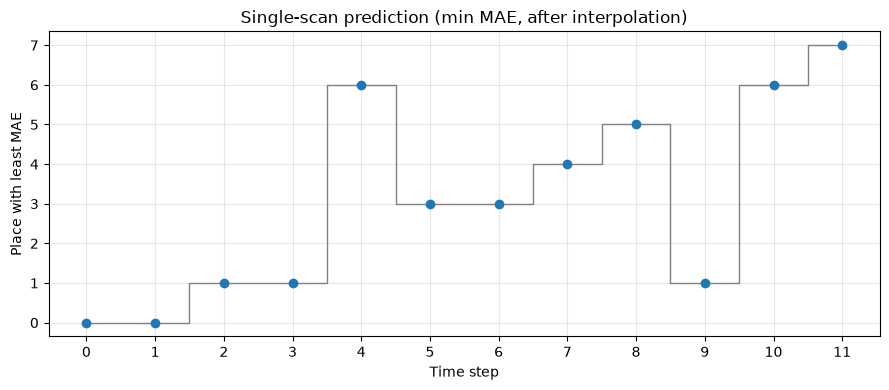

[0, 0, 1, 1, 6, 3, 3, 4, 5, 1, 6, 7]


In [6]:
best_clean = mae_clean.argmin(axis=1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.step(obs.time_step, best_clean, where='mid', color='gray', lw=1)
ax.plot(obs.time_step, best_clean, 'o', color='tab:blue')
ax.set(xlabel='Time step', ylabel='Place with least MAE', title='Single-scan prediction (min MAE, after interpolation)', yticks=range(8), xticks=obs.time_step)
ax.grid(alpha=.3); plt.tight_layout(); plt.show()
print(best_clean.tolist())

# Q4 (c): Belief filter
Prior 0.5 on places 0 and 4. Each step: predict from odometry (skipped at step 0), then update with the scan.

### Scan-fit rule
- E_t(j) = mean over 31 beams of |z_t(k) − r_j(k)|, and L_t(j) = exp(−E_t(j) / 0.15).
- Motion: move = 0.8 next / 0.2 stay; stay = 0.9 stay / 0.1 next (7 → 0).
- **Why 0.15:** it sets how strict the filter is. A large value (1) makes the scan barely matter (0.905 vs 0.819 for errors 0.10 vs 0.20). A tiny value (0.01) lets one noisy scan decide everything. 0.15 gives 0.513 vs 0.264, favouring the better match without overconfidence.

In [7]:
TAU = 0.15
b = np.zeros(8); b[[0, 4]] = 0.5                           # prior
E = np.abs(O[:, None, :] - R[None, :, :]).mean(axis=2)     # (12, 8) mean absolute error
L = np.exp(-E / TAU)                                       # (12, 8) likelihood

def predict(b, action):
    follow, other = (0.8, 0.2) if action == 'move' else (0.9, 0.1)
    nxt = np.roll(b, 1)                                    # belief shifted one place forward (7 -> 0)
    return follow * nxt + other * b if action == 'move' else follow * b + other * nxt

B = []
for t in range(len(O)):
    if t > 0:
        b = predict(b, obs.odometry[t])
    b = b * L[t]
    b = b / b.sum()
    B.append(b)
B = np.array(B)
assert np.allclose(B.sum(axis=1), 1)

df = pd.DataFrame(B.round(3), index=pd.Index(obs.time_step, name='time step'), columns=[f'place {p}' for p in range(8)])
df['sum'] = B.sum(axis=1).round(3)
df['most likely'] = B.argmax(axis=1)
df

,place 0,place 1,place 2,place 3,place 4,place 5,place 6,place 7,sum,most likely
time step,,,,,,,,,,
0,0.502,0.000,0.000,0.000,0.498,0.000,0.000,0.000,1.0,0
1,0.495,0.024,0.000,0.000,0.460,0.021,0.000,0.000,1.0,0
2,0.050,0.467,0.010,0.000,0.051,0.414,0.008,0.000,1.0,1
3,0.025,0.499,0.021,0.000,0.028,0.410,0.017,0.000,1.0,1
4,0.001,0.059,0.450,0.015,0.001,0.057,0.405,0.013,1.0,2
5,0.000,0.002,0.101,0.425,0.001,0.002,0.096,0.373,1.0,3
6,0.001,0.000,0.053,0.480,0.002,0.000,0.055,0.409,1.0,3
7,0.443,0.001,0.001,0.006,0.542,0.001,0.001,0.005,1.0,4
8,0.039,0.387,0.001,0.001,0.052,0.518,0.001,0.001,1.0,5


# Q4 (d): Belief heatmap

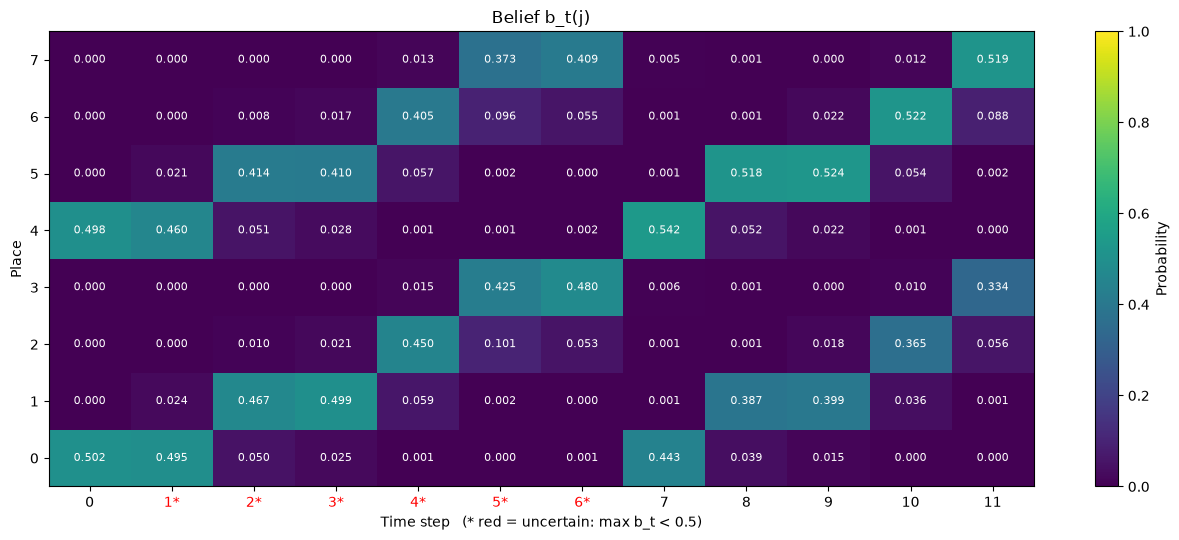

max b_t per step: [0.502, 0.495, 0.467, 0.499, 0.45, 0.425, 0.48, 0.542, 0.518, 0.524, 0.522, 0.519]
uncertain steps : [1, 2, 3, 4, 5, 6]


In [8]:
THRESH = 0.5
uncertain = B.max(axis=1) < THRESH

fig, ax = plt.subplots(figsize=(13, 5.5))
im = ax.imshow(B.T, origin='lower', aspect='auto', cmap='viridis', vmin=0, vmax=1)
for t in range(B.shape[0]):
    for j in range(8):
        ax.text(t, j, f'{B[t, j]:.3f}', ha='center', va='center', fontsize=8, color='white' if B[t, j] < 0.6 else 'black')
ax.set_xticks(range(12))
ax.set_xticklabels([f'{t}*' if u else str(t) for t, u in zip(range(12), uncertain)])
for lab, u in zip(ax.get_xticklabels(), uncertain):
    if u: lab.set_color('red')
ax.set(xlabel=f'Time step   (* red = uncertain: max b_t < {THRESH})', ylabel='Place', title='Belief b_t(j)', yticks=range(8))
fig.colorbar(im, ax=ax, label='Probability')
plt.tight_layout(); plt.show()
print('max b_t per step:', B.max(axis=1).round(3).tolist())
print('uncertain steps :', np.where(uncertain)[0].tolist())

### Uncertainty rule
Uncertain if the most likely place has probability below 0.5.

In [9]:
order = np.argsort(-B, axis=1)
top, second = order[:, 0], order[:, 1]
p1, p2 = B[np.arange(12), top], B[np.arange(12), second]
uncertain = p1 < THRESH
pd.DataFrame({'most likely': top, 'p': p1.round(3), 'runner-up': second, 'p ': p2.round(3), 'uncertain': uncertain},
             index=pd.Index(obs.time_step, name='time step')).T

time step,0,1,2,3,4,5,6,7,8,9,10,11
most likely,0,0,1,1,2,3,3,4,5,5,6,7
p,0.502,0.495,0.467,0.499,0.45,0.425,0.48,0.542,0.518,0.524,0.522,0.519
runner-up,4,4,5,5,6,7,7,0,1,1,2,3
p,0.498,0.46,0.414,0.41,0.405,0.373,0.409,0.443,0.387,0.399,0.365,0.334
uncertain,False,True,True,True,True,True,True,False,False,False,False,False


### Filter vs single-scan baseline

In [10]:
filt = B.argmax(axis=1)
base = mae_clean.argmin(axis=1)                        # single-scan baseline from part (b), after interpolation
first = int(np.argmax(filt != base))
print('filter  :', filt.tolist())
print('baseline:', base.tolist())
print('first disagreement at step', first, f'(filter {filt[first]} with p={B[first, filt[first]]:.3f}, baseline {base[first]} with p={B[first, base[first]]:.3f})')
print('steps where they disagree:', np.where(filt != base)[0].tolist())

filter  : [0, 0, 1, 1, 2, 3, 3, 4, 5, 5, 6, 7]
baseline: [0, 0, 1, 1, 6, 3, 3, 4, 5, 1, 6, 7]
first disagreement at step 4 (filter 2 with p=0.450, baseline 6 with p=0.405)
steps where they disagree: [4, 9]


### Which answer to trust
First disagreement: step 4 (filter 2, baseline 6). **Trust the filter.** It also uses the "move" message and the earlier belief (step 3: place 1 at 0.499 ahead of its twin 5 at 0.410, so a move gives 2). The baseline sees only this scan, where twins 6 and 2 are nearly tied (0.141 vs 0.155).

### Against the true route (evaluation only)

In [11]:
true = pd.read_csv(D + 'route_reference.csv').true_place.values
print('true    :', true.tolist())
print(f'baseline accuracy: {(base == true).mean():.2f}')
print(f'filter accuracy  : {(filt == true).mean():.2f}')
print(f'mean probability on the true place (filter): {B[np.arange(12), true].mean():.3f}')
print('probability on the true place per step:', B[np.arange(12), true].round(3).tolist())

true    : [0, 0, 1, 1, 2, 3, 3, 4, 5, 5, 6, 7]
baseline accuracy: 0.83
filter accuracy  : 1.00
mean probability on the true place (filter): 0.495
probability on the true place per step: [0.502, 0.495, 0.467, 0.499, 0.45, 0.425, 0.48, 0.542, 0.518, 0.524, 0.522, 0.519]


# Q4 (e): Corrupted beams (seed 42)
Each scan: k random beams replaced by random values in [0.5, 4.5] m.

In [12]:
def run_filter(scans):
    b = np.zeros(8); b[[0, 4]] = 0.5
    out = []
    for t in range(len(scans)):
        if t > 0:
            b = predict(b, obs.odometry[t])
        b = b * np.exp(-np.abs(scans[t][None, :] - R).mean(axis=1) / TAU)
        b = b / b.sum()
        out.append(b)
    return np.array(out)

def corrupt(k, seed=42):
    rng = np.random.default_rng(seed)
    S = O.copy()
    for t in range(len(S)):
        idx = rng.choice(31, k, replace=False)
        S[t, idx] = rng.uniform(0.5, 4.5, k)
    return S

assert np.allclose(run_filter(O), B)                      # clean run reproduces part (c)

rows, runs = [], {}
for k in [0, 3, 5, 8, 12]:
    Bk = run_filter(corrupt(k)) if k else B
    runs[k] = Bk
    wrong = Bk.argmax(axis=1) != true
    unc = Bk.max(axis=1) < THRESH
    rows.append({'corrupted beams / scan': k, 'accuracy': round((~wrong).mean(), 2),
                 'mean p(true place)': round(Bk[np.arange(12), true].mean(), 3),
                 'uncertain steps': int(unc.sum()), 'wrong steps': np.where(wrong)[0].tolist(),
                 'wrong and not uncertain': np.where(wrong & ~unc)[0].tolist()})
pd.DataFrame(rows).set_index('corrupted beams / scan')

,accuracy,mean p(true place),uncertain steps,wrong steps,wrong and not uncertain
corrupted beams / scan,,,,,
0,1.00,0.495,6,[],[]
3,1.00,0.493,6,[],[]
5,1.00,0.470,9,[],[]
8,1.00,0.462,10,[],[]
12,0.83,0.440,10,"[0, 1]",[0]


### Result
- Up to 8 corrupted beams: accuracy stays 1.00, but p(true place) drops (0.495 → 0.462) and uncertain steps rise (6 → 10).
- At 12 beams, steps 0 and 1 go wrong. Twin places differ by only ~0.015 m in mean error, so random corruption decides between them.

In [13]:
# how well can one scan separate twin places (j, j+4)? only beams -55, -50, -45 differ
ang = np.arange(-75, 80, 5)
sigma = np.median(mae.min(axis=1)[~(O >= 4.5).any(axis=1)]) * np.sqrt(np.pi / 2)   # per-beam noise from the clean steps (Gaussian: MAE = 0.8 sigma)
d = np.abs(R[0] - R[4]); sel = d > 0.05
print('beams (deg):', ang[sel].tolist(), ' twin difference (m):', d[sel].round(3).tolist(), f' sigma = {sigma:.3f} m')
sep = np.sqrt((d ** 2).sum()) / sigma
print(f'separation: {sep:.1f} sigma with 1 scan, {sep * 2:.1f} sigma averaging 4 scans')

beams (deg): [-55, -50, -45]  twin difference (m): [0.087, 0.156, 0.13]  sigma = 0.110 m
separation: 2.1 sigma with 1 scan, 4.1 sigma averaging 4 scans


### Extra observation
Twins (j, j+4) differ only on beams −55°, −50°, −45° (up to 0.156 m, vs noise σ = 0.11 m): 2.1σ per scan. **Proposal:** stay put and average 4 scans (4.1σ). Moving doesn't help, since every place has a twin.